Tutorial: geometrically non-linear benchmarks with pyfe3d.solver
===

Two benchmarks of Sze, K. Y., Liu, X. H. and Lo, S. H., Popular benchmark
problems for geometric nonlinear analysis of shells, *Finite Elements in
Analysis and Design*, 40(11), 1551-1569, 2004,
[doi:10.1016/j.finel.2003.11.001](https://doi.org/10.1016/j.finel.2003.11.001),
solved with the non-linear static analyses of `pyfe3d.solver.Analysis`:

- cantilever under an end moment (Section 3.2, Fig. 3, Table 3), with the
  Newton-Raphson method;
- hinged cylindrical roof under a central point load (Section 3.8, Fig. 9,
  Tables 9a and 9d), whose snap-through, and snap-back for the thinner roof,
  are traced with the arc-length methods.

Sze et al. (2004) computed their reference values with ABAQUS's S4R element,
a finite-strain shell element with an updated Lagrangian formulation (their
Table 1). The elements of pyfe3d use the von Karman strains, valid for small
strains and moderate rotations, in a total Lagrangian formulation whose
element coordinate systems are not updated. The convergence of every
increment is checked with Crisfield's criterion, the default of `Analysis`
(`convergence='crisfield'`, `relTOL=1e-9`).

The models are those of `tests/test_nonlinear_benchmarks_sze2004.py`, whose
`Model` class, from `tests/test_solver_nonlinear_static.py`, provides the
callables `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of `Analysis` for
a list of pyfe3d elements. A last section measures the sensitivity of the
roof to the transverse hourglass stiffness of `Quad4R`. The cells below run
in about five minutes.

In [1]:
import os
import sys
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

from test_nonlinear_benchmarks_sze2004 import (
    CANTILEVER, TABLE_3A_EXACT, TABLE_9A, TABLE_9D, ROOF, elastica_tip,
    von_karman_tip, cantilever_end_moment, run_cantilever_end_moment,
    hinged_roof, run_hinged_roof, compare_with_table_9a, limit_points,
    linear_roof_WC, ritz_roof_WC)

Cantilever under an end moment
---

Fig. 3a of Sze et al. (2004): $L = 12$, width $b = 1$, thickness $h = 0.1$,
$E = 1.2 \times 10^6$, $\nu = 0$, $M_o = E I/L = 25/3$ and
$M_{max} = 2 \pi M_o$. Under the end moment $M$ the cantilever bends into a
circular arc of radius $E I/M$ and the exact tip deflections are

$$
\frac{U}{L} = \frac{M_o}{M} \sin\frac{M}{M_o} - 1, \qquad
\frac{W}{L} = \frac{M_o}{M} \left(1 - \cos\frac{M}{M_o}\right)
$$

such that at $M_{max}$ the cantilever is a full circle and the tip is back at
the root. The text of Section 3.2 gives $M_{max} = \pi M_o$; Fig. 3a and the
exact values of Table 3a, e.g. $-U = 12$, $W = 0$ at $M/M_{max} = 1$,
correspond to $M_{max} = 2 \pi M_o$, used here.

With the von Karman axial strain $\epsilon_{xx} = u_{,x} + w_{,x}^2/2$ the
free end gives a null axial force, the bending equation is that of the linear
theory and

$$
\frac{W}{L} = \frac{\varphi}{2}, \qquad \frac{U}{L} = -\frac{\varphi^2}{6},
\qquad \varphi = \frac{M L}{E I}
$$

the first terms of the expansion of the exact solution in the tip rotation
$\varphi$. The von Karman cantilever never rolls up into a circle.

The cantilever is modelled with a strip of $16 \times 1$ `Quad4R` elements,
as the $16 \times 1$ S4R mesh of Table 3a, and loaded in 20 equal increments
of the Newton-Raphson method, `initialInc = maxInc = 0.05`.

In [2]:
L = CANTILEVER['L']
m, U, W = run_cantilever_end_moment('Quad4R', 16, inc=0.05)
U_vk, W_vk = von_karman_tip(m)
print('Newton-Raphson, 16x1 Quad4R: %d increments' % len(m))
print()
print('%7s | %8s %8s %8s | %8s %8s %8s'
      % ('', '-U_tip', '', '', 'W_tip', '', ''))
print('%7s | %8s %8s %8s | %8s %8s %8s'
      % ('M/Mmax', 'Table 3a', 'v. Karm.', 'Quad4R', 'Table 3a', 'v. Karm.',
         'Quad4R'))
for (mr, Ur, Wr), mi, Ui, Wi, Uv, Wv in zip(TABLE_3A_EXACT, m, U, W, U_vk,
                                           W_vk):
    assert np.isclose(mr, mi)
    print('%7.2f | %8.3f %8.3f %8.3f | %8.3f %8.3f %8.3f'
          % (mr, Ur, L*Uv, L*Ui, Wr, L*Wv, L*Wi))
print()
print('check: Quad4R against the von Karman solution, max relative '
      'difference W %.1e, U %.1e' % (np.abs(W/W_vk - 1).max(),
                                     np.abs(U/U_vk - 1).max()))
print('check: Quad4R against Table 3a (exact) at M/Mmax = 0.05: '
      'W %+.2f %%, -U %+.2f %%'
      % (100*(L*W[0]/TABLE_3A_EXACT[0, 2] - 1),
         100*(L*U[0]/TABLE_3A_EXACT[0, 1] - 1)))

Newton-Raphson, 16x1 Quad4R: 20 increments

        |   -U_tip                   |    W_tip                  
 M/Mmax | Table 3a v. Karm.   Quad4R | Table 3a v. Karm.   Quad4R
   0.05 |    0.196    0.197    0.197 |    1.870    1.885    1.885
   0.10 |    0.774    0.790    0.789 |    3.648    3.770    3.770
   0.15 |    1.699    1.777    1.775 |    5.248    5.655    5.655
   0.20 |    2.918    3.158    3.155 |    6.598    7.540    7.540
   0.25 |    4.361    4.935    4.930 |    7.639    9.425    9.425
   0.30 |    5.945    7.106    7.099 |    8.333   11.310   11.310
   0.35 |    7.585    9.672    9.663 |    8.664   13.195   13.195
   0.40 |    9.194   12.633   12.621 |    8.637   15.080   15.080
   0.45 |   10.688   15.989   15.973 |    8.281   16.965   16.965
   0.50 |   12.000   19.739   19.720 |    7.639   18.850   18.850
   0.55 |   13.073   23.884   23.861 |    6.775   20.735   20.735
   0.60 |   13.871   28.424   28.397 |    5.758   22.619   22.619
   0.65 |   14.377   33.359   33

The `Quad4R` strip reproduces the von Karman solution: the deflection exactly,
the axial displacement within 0.1 %, converging with the mesh. It agrees with
the exact values of Table 3a only for small tip rotations, within 1 % at
$M = 0.05 M_{max}$ (tip rotation of 0.31 rad), and departs from them beyond.
The same analysis with 16 `BeamC` elements is plotted below.

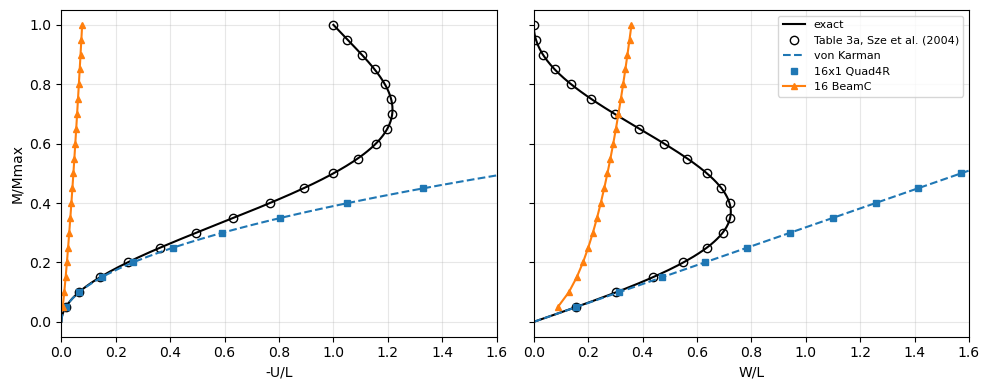

In [3]:
mb, Ub, Wb = run_cantilever_end_moment('BeamC', 16, inc=0.05)
mm = np.linspace(0, 1, 201)
Ue, We = elastica_tip(mm)
Uv, Wv = von_karman_tip(mm)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, label, exact, vk, quad, beam, table in [
        (axes[0], '-U/L', Ue, Uv, U, Ub, TABLE_3A_EXACT[:, 1]/L),
        (axes[1], 'W/L', We, Wv, W, Wb, TABLE_3A_EXACT[:, 2]/L)]:
    ax.plot(exact, mm, 'k-', lw=1.5, label='exact')
    ax.plot(table, TABLE_3A_EXACT[:, 0], 'ko', mfc='none',
            label='Table 3a, Sze et al. (2004)')
    ax.plot(vk, mm, 'C0--', lw=1.5, label='von Karman')
    ax.plot(quad, m, 'C0s', ms=5, label='16x1 Quad4R')
    ax.plot(beam, mb, 'C1^-', ms=5, label='16 BeamC')
    ax.set_xlabel(label)
    ax.set_xlim(0, 1.6)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('M/Mmax')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

The deformed cantilever at $M = 0.1 M_{max}$, $0.2 M_{max}$ and
$0.35 M_{max}$, the last one the first configuration of Fig. 3c of Sze et al.
(2004): the exact circular arcs and the edge $y = 0$ of the `Quad4R` strip,
both without amplification.

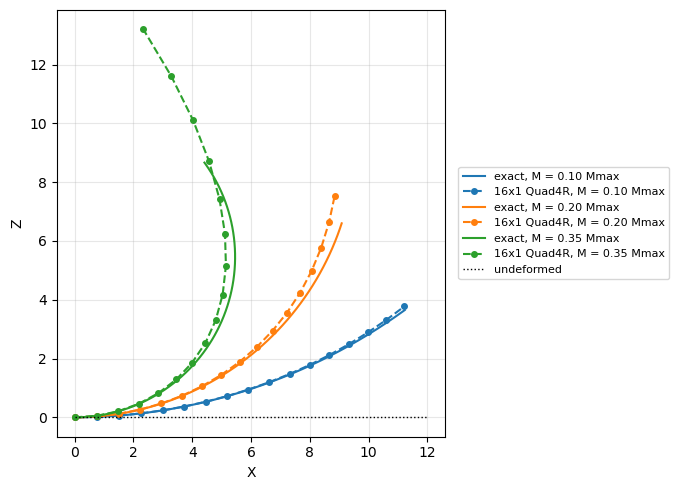

In [4]:
model, bu, tip_deflections, Mmax = cantilever_end_moment('Quad4R', 16)
an = model.analysis(bu, NL_method='NR', initialInc=0.05, maxInc=0.05)
increments, cs = an.static(NLgeom=True, silent=True)
x = model.x.reshape(-1, 3)
edge = np.isclose(x[:, 1], 0.)
s = np.linspace(0, L, 200)
fig, ax = plt.subplots(figsize=(8, 5))
for k, (frac, color) in enumerate([(0.1, 'C0'), (0.2, 'C1'), (0.35, 'C2')]):
    i = int(np.argmin(np.abs(np.array(increments) - frac)))
    u = cs[i].reshape(-1, 6)
    radius = L/(2*np.pi*frac)
    ax.plot(radius*np.sin(s/radius), radius*(1 - np.cos(s/radius)), '-',
            color=color, lw=1.5, label='exact, M = %.2f Mmax' % frac)
    ax.plot(x[edge, 0] + u[edge, 0], x[edge, 2] + u[edge, 2], 'o--',
            color=color, ms=4, label='16x1 Quad4R, M = %.2f Mmax' % frac)
ax.plot([0, L], [0, 0], 'k:', lw=1, label='undeformed')
ax.set_aspect('equal')
ax.set_xlabel('X')
ax.set_ylabel('Z')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

The beam elements `BeamC` and `BeamLR` interpolate the axial displacement
linearly and integrate the von Karman axial strain with Gauss points along
the element, where $w_{,x}^2$ is not constant: the axial strain cannot vanish
in the element and the cantilever is too stiff (membrane locking). The
stiffening grows with the moment and decreases with the number of elements;
at $M = 0.05 M_{max}$:

In [5]:
print('%-7s %9s %10s %12s %10s' % ('element', 'elements', 'W_tip',
                                   'von Karman', 'error %'))
for name in ['BeamC', 'BeamLR']:
    for n in [16, 64, 256]:
        mi, Ui, Wi = run_cantilever_end_moment(name, n, inc=0.25, m_max=0.05)
        Wv = von_karman_tip(mi[-1])[1]
        print('%-7s %9d %10.4f %12.4f %10.2f'
              % (name, n, L*Wi[-1], L*Wv, 100*(Wi[-1]/Wv - 1)))
print('Table 3a (exact) at M/Mmax = 0.05: W_tip %.3f' % TABLE_3A_EXACT[0, 2])

element  elements      W_tip   von Karman    error %
BeamC          16     1.0636       1.8850     -43.57
BeamC          64     1.6477       1.8850     -12.59
BeamC         256     1.8621       1.8850      -1.21
BeamLR         16     1.0637       1.8850     -43.57


BeamLR         64     1.6477       1.8850     -12.59
BeamLR        256     1.8621       1.8850      -1.21
Table 3a (exact) at M/Mmax = 0.05: W_tip 1.870


Hinged cylindrical roof, 12.7 thick
---

Fig. 9a of Sze et al. (2004): cylindrical roof of radius $R = 2540$, length
$2L$ with $L = 254$ along the axis, opening $2\theta$ with
$\theta = 0.1$ rad, thickness $h = 12.7$, $E = 3102.75$, $\nu = 0.3$,
central point load $P$ with $P_{max} = 3000$. The straight edges are hinged,
with all the translations restrained, the curved edges are free. One quarter
is modelled, with symmetry conditions on the planes through the centre C, as
in Sze et al. (2004), who used $16 \times 16$ S4R elements and Riks' method
(Table 9a).

Here one quarter is meshed with $16 \times 16$ flat `Quad4R` elements and the
path is traced with Crisfield's arc-length method up to $1.2 P_{max}$, with
the arc-length increment of `initialInc = maxInc = 0.05`. The load factor
decreases past the limit points, where the tangent stiffness matrix is
singular, which the Newton-Raphson method cannot pass.

In [6]:
P16, W16 = run_hinged_roof(n=16, NL_method='arc_length_crisfield')
P_riks, W_riks = run_hinged_roof(n=16, NL_method='arc_length_riks')
P_nr, W_nr = run_hinged_roof(n=16, NL_method='NR', load_factor=1.)
print("Crisfield's arc-length method: %d increments, P/Pmax %.3f at -W_C %.3f"
      % (len(P16) - 1, P16[-1], W16[-1]))
print("Riks' arc-length method: %d increments, P/Pmax %.3f at -W_C %.3f"
      % (len(P_riks) - 1, P_riks[-1], W_riks[-1]))
print('Newton-Raphson: %d increments, stops at P/Pmax %.4f, -W_C %.3f'
      % (len(P_nr) - 1, P_nr[-1], W_nr[-1]))

P_calc = compare_with_table_9a(P16, W16)
P_riks_calc = compare_with_table_9a(P_riks, W_riks)
print()
print('%8s %10s %10s %10s %10s' % ('-W_C', 'Table 9a', 'pyfe3d', 'diff',
                                   'diff %'))
for (Pr, Wr), Pc in zip(TABLE_9A, P_calc):
    print('%8.3f %10.4f %10.4f %+10.4f %+10.2f'
          % (Wr, Pr, Pc, Pc - Pr, 100*(Pc - Pr)/Pr))
print()
(Pa, Wa), (Pb, Wb) = limit_points(P16, W16, 15.)
(Pa_r, Wa_r), (Pb_r, Wb_r) = limit_points(TABLE_9A[:, 0], TABLE_9A[:, 1], 15.)
print('%-18s %16s %16s' % ('', 'Table 9a', 'pyfe3d'))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('upper limit point', Pa_r, Wa_r, Pa, Wa, 100*(Pa/Pa_r - 1)))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('lower limit point', Pb_r, Wb_r, Pb, Wb, 100*(Pb/Pb_r - 1)))
print()
print("check: Riks' and Crisfield's methods, max difference of P/Pmax at the "
      "deflections of Table 9a %.1e" % np.abs(P_riks_calc - P_calc).max())

Crisfield's arc-length method: 84 increments, P/Pmax 1.200 at -W_C 29.800
Riks' arc-length method: 84 increments, P/Pmax 1.200 at -W_C 29.800
Newton-Raphson: 20 increments, stops at P/Pmax 0.7459, -W_C 10.033

    -W_C   Table 9a     pyfe3d       diff     diff %
   0.693     0.0877     0.0941    +0.0064      +7.33
   1.638     0.1980     0.2126    +0.0146      +7.39
   3.087     0.3473     0.3718    +0.0245      +7.06
   4.477     0.4686     0.4991    +0.0305      +6.50
   5.802     0.5647     0.5971    +0.0324      +5.74
   7.057     0.6381     0.6686    +0.0305      +4.78
   8.237     0.6908     0.7158    +0.0250      +3.62
   9.339     0.7246     0.7407    +0.0161      +2.22
  10.358     0.7412     0.7449    +0.0037      +0.50
  11.293     0.7421     0.7315    -0.0106      -1.43
  12.141     0.7286     0.7027    -0.0259      -3.56
  12.903     0.7023     0.6618    -0.0405      -5.76
  13.583     0.6649     0.6132    -0.0517      -7.78
  14.188     0.6182     0.5600    -0.0582      -

The pyfe3d values are interpolated linearly along the computed path at the
deflections of Table 9a, and the limit points of Table 9a are its largest and
smallest tabulated loads (the table samples the path, the limit points may
lie between its points). Both arc-length methods trace the same path, and
the Newton-Raphson method stops at the upper limit point.

The limit loads agree within about 1 % with Table 9a. Along the path the
differences are larger: pyfe3d is about 7 % stiffer at the start of the path
and the descending branch lies below the reference values by up to about
0.06 $P_{max}$. Most of the stiffening at the start of the path comes from
the transverse hourglass stiffness of `Quad4R`, see the
[last section](#Sensitivity-to-the-transverse-hourglass-stiffness-of-Quad4R).
The mesh convergence of the pyfe3d path is shown below, comparing
$8 \times 8$, $16 \times 16$ and $32 \times 32$ meshes, the last one with a
larger arc-length increment.

 8x8  Quad4R: limit loads 0.7467, 0.1753; P/Pmax at -W_C = 0.693: 0.0957 (Table 9a 0.0877)
16x16 Quad4R: limit loads 0.7459, 0.1713; P/Pmax at -W_C = 0.693: 0.0941 (Table 9a 0.0877)
32x32 Quad4R: limit loads 0.7446, 0.1704; P/Pmax at -W_C = 0.693: 0.0931 (Table 9a 0.0877)


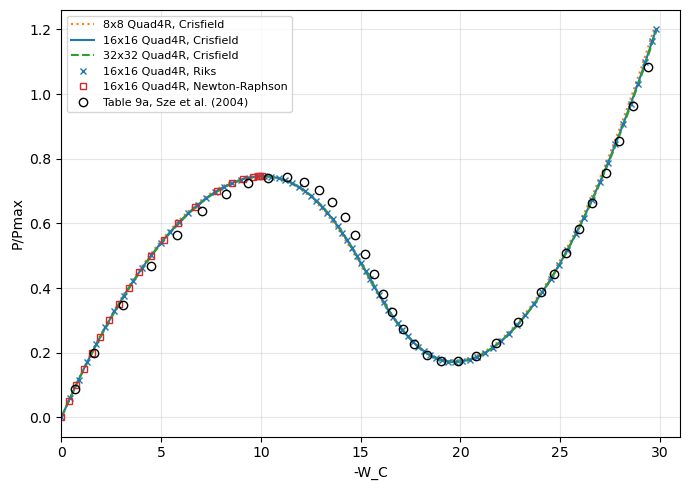

In [7]:
P8, W8 = run_hinged_roof(n=8)
P32, W32 = run_hinged_roof(n=32, initialInc=0.1, maxInc=0.1)
for n, (P, W) in [(8, (P8, W8)), (16, (P16, W16)), (32, (P32, W32))]:
    (Pa, Wa), (Pb, Wb) = limit_points(P, W, 15.)
    Pc = compare_with_table_9a(P, W)
    print('%2dx%-2d Quad4R: limit loads %.4f, %.4f; P/Pmax at -W_C = %.3f: '
          '%.4f (Table 9a %.4f)' % (n, n, Pa, Pb, TABLE_9A[0, 1], Pc[0],
                                    TABLE_9A[0, 0]))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(W8, P8, 'C1:', lw=1.5, label='8x8 Quad4R, Crisfield')
ax.plot(W16, P16, 'C0-', lw=1.5, label='16x16 Quad4R, Crisfield')
ax.plot(W32, P32, 'C2--', lw=1.5, label='32x32 Quad4R, Crisfield')
ax.plot(W_riks, P_riks, 'C0x', ms=5, label='16x16 Quad4R, Riks')
ax.plot(W_nr, P_nr, 'C3s', ms=5, mfc='none', label='16x16 Quad4R, Newton-Raphson')
ax.plot(TABLE_9A[:, 1], TABLE_9A[:, 0], 'ko', mfc='none',
        label='Table 9a, Sze et al. (2004)')
ax.set_xlabel('-W_C')
ax.set_ylabel('P/Pmax')
ax.set_xlim(0, 31)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

Hinged cylindrical roof, 6.35 thick
---

The same roof with half the thickness, $h = 6.35$, Table 9d of Sze et al.
(2004), computed with $24 \times 24$ S4R elements on one quarter. Past the
upper limit point the load becomes negative and the path turns back in the
deflection (snap-back) twice before stiffening. One quarter with
$24 \times 24$ `Quad4R` elements, Crisfield's arc-length method up to
$1.1 P_{max}$ with `initialInc = maxInc = 0.02`.

Crisfield's arc-length method: 117 increments, P/Pmax 1.100 at -W_C 38.648
turning points of -W_C (snap-back): P/Pmax -0.0139 at -W_C 17.186, P/Pmax -0.1336 at -W_C 14.850

                           Table 9d           pyfe3d
upper limit point   0.1953 at 12.89  0.1944 at 12.02  -0.47 %
lower limit point  -0.1288 at 15.78 -0.1436 at 16.24 +11.53 %


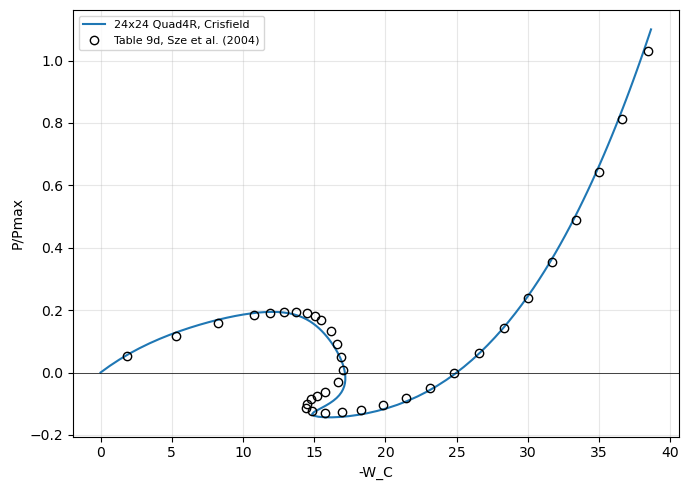

In [8]:
P, W = run_hinged_roof(n=24, h=6.35, load_factor=1.1, initialInc=0.02,
                       maxInc=0.02)
print("Crisfield's arc-length method: %d increments, P/Pmax %.3f at -W_C %.3f"
      % (len(P) - 1, P[-1], W[-1]))
dW = np.diff(W)
turns = np.flatnonzero(np.sign(dW[1:]) != np.sign(dW[:-1])) + 1
print('turning points of -W_C (snap-back): %s' % ', '.join(
    'P/Pmax %.4f at -W_C %.3f' % (P[i], W[i]) for i in turns))
(Pa, Wa), _ = limit_points(P, W, 13.5)
(Pa_r, Wa_r), _ = limit_points(TABLE_9D[:, 0], TABLE_9D[:, 1], 13.5)
i_min, i_min_r = np.argmin(P), np.argmin(TABLE_9D[:, 0])
print()
print('%-18s %16s %16s' % ('', 'Table 9d', 'pyfe3d'))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('upper limit point', Pa_r, Wa_r, Pa, Wa, 100*(Pa/Pa_r - 1)))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('lower limit point', TABLE_9D[i_min_r, 0], TABLE_9D[i_min_r, 1],
         P[i_min], W[i_min], 100*(P[i_min]/TABLE_9D[i_min_r, 0] - 1)))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(W, P, 'C0-', lw=1.5, label='24x24 Quad4R, Crisfield')
ax.plot(TABLE_9D[:, 1], TABLE_9D[:, 0], 'ko', mfc='none',
        label='Table 9d, Sze et al. (2004)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('-W_C')
ax.set_ylabel('P/Pmax')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

The upper limit load agrees with the largest load of Table 9d within 0.5 %;
the lower limit load of pyfe3d, negative, is lower than the smallest load of
Table 9d, by about 0.015 $P_{max}$.

Sensitivity to the transverse hourglass stiffness of Quad4R
---

`Quad4R` integrates its stiffness with one point at the centroid and
controls the hourglass modes with the artificial stiffnesses of Brockman,
R. A., Dynamics of the bilinear Mindlin plate element, *International
Journal for Numerical Methods in Engineering*, 24(12), 2343-2356, 1987,
[doi:10.1002/nme.1620241208](https://doi.org/10.1002/nme.1620241208), see
the Notes of `pyfe3d.quad4r`. The transverse one keeps Brockman's factor
$1/(1 + 1/A)$, $A$ being the element area,

$$
E^{(h)}_w = \frac{0.05 \, f_w (E_{1eq} + E_{2eq}) h^3}{1 + 1/A}
= \frac{0.1 \, f_w E h^3}{1 + 1/A} \quad \text{(isotropic)}
$$

with $f_w$ = `hgfactor_w`, `1` by default. The elements of the quarter of the
roof have areas from 16 ($64 \times 64$) to 1008 ($8 \times 8$) in the unit
of length of the model, so that the default $E^{(h)}_w$ is 0.94 to 1.0 times
$0.1 E h^3$. The hourglass operator cannot distinguish the spurious pattern
$w = x y$ from a twist curvature, and this stiffness also stiffens the
twist, by the ratio $3 E^{(h)}_w/(E h^3)$, about 30 % here. As documented in
`pyfe3d.quad4r`, the amount of hourglass stiffness that is acceptable
depends on the problem. The default follows the references documented
there and is used in all the comparisons with Sze et al. (2004) above. The
values of `hgfactor_w` below measure the sensitivity of this problem only:
none of them is a recommendation, and new default values would require
more studies.

Two references without hourglass control are used:

- `Tria3DSG`, with the same meshes split into two triangles per
  quadrilateral;
- the linear shallow-shell (Donnell-Marguerre) Kirchhoff solution of
  `ritz_roof_WC`, a Ritz method with the Legendre-based functions of
  Castro, S. G. P. and Donadon, M. V., *Composite Structures*, 160,
  232-247, 2017,
  [doi:10.1016/j.compstruct.2016.10.026](https://doi.org/10.1016/j.compstruct.2016.10.026),
  `m` functions per direction for each of $u$, $v$ and $w$. It has no
  transverse shear deformation, so the finite elements are compared with it
  with their transverse shear stiffnesses $A_{44}$, $A_{45}$ and $A_{55}$
  multiplied by 100 (`shear_factor=100.` of `hinged_roof`).

The linear deflection $-W_C$ of the 12.7 thick roof under $P_{max}$:

In [9]:
HGFACTORS = [1., 0.1, 0.03, 0.01, 0.002, 0.0002]
MESHES = [16, 32, 64]
W_ritz = {m: ritz_roof_WC(m) for m in (20, 30)}
print('shallow-shell Kirchhoff Ritz solution: -W_C %.4f (m = 20), %.4f '
      '(m = 30)' % (W_ritz[20], W_ritz[30]))
rows = [('Tria3DSG', dict(element='Tria3DSG'))] + [
    ('Quad4R, hgfactor_w = %g' % hg, dict(hgfactor_w=hg)) for hg in HGFACTORS]
for shear_factor, ref_name in [(1., 'Tria3DSG'), (100., 'Ritz')]:
    W_lin = {name: [linear_roof_WC(n, shear_factor=shear_factor, **kw)
                    for n in MESHES] for name, kw in rows}
    ref = (W_lin['Tria3DSG'][-1] if ref_name == 'Tria3DSG'
           else W_ritz[30])
    print()
    print('linear -W_C under P_max, h = 12.7, transverse shear stiffness '
          'x%g' % shear_factor)
    print('%-28s' % '' + ''.join('%9s' % ('%dx%d' % (n, n)) for n in MESHES)
          + '   64x64 vs %s' % ref_name)
    for name, _ in rows:
        Wn = W_lin[name]
        print('%-28s' % name + ''.join('%9.4f' % Wi for Wi in Wn)
              + '   %+8.2f %%' % (100*(Wn[-1]/ref - 1)))

shallow-shell Kirchhoff Ritz solution: -W_C 7.4798 (m = 20), 7.4801 (m = 30)



linear -W_C under P_max, h = 12.7, transverse shear stiffness x1
                                16x16    32x32    64x64   64x64 vs Tria3DSG
Tria3DSG                       7.5480   7.6295   7.6733      +0.00 %
Quad4R, hgfactor_w = 1         7.0949   7.1372   7.1668      -6.60 %
Quad4R, hgfactor_w = 0.1       7.5543   7.6061   7.6255      -0.62 %
Quad4R, hgfactor_w = 0.03      7.6170   7.6698   7.6882      +0.19 %
Quad4R, hgfactor_w = 0.01      7.6494   7.7026   7.7206      +0.62 %
Quad4R, hgfactor_w = 0.002     7.6825   7.7378   7.7557      +1.07 %
Quad4R, hgfactor_w = 0.0002    7.7031   7.7816   7.8003      +1.65 %



linear -W_C under P_max, h = 12.7, transverse shear stiffness x100
                                16x16    32x32    64x64   64x64 vs Ritz
Tria3DSG                       7.3996   7.4626   7.4795      -0.01 %
Quad4R, hgfactor_w = 1         6.9602   7.0050   7.0348      -5.95 %
Quad4R, hgfactor_w = 0.1       7.3562   7.4083   7.4272      -0.71 %
Quad4R, hgfactor_w = 0.03      7.3940   7.4469   7.4646      -0.21 %
Quad4R, hgfactor_w = 0.01      7.4050   7.4583   7.4756      -0.06 %
Quad4R, hgfactor_w = 0.002     7.4095   7.4630   7.4802      +0.00 %
Quad4R, hgfactor_w = 0.0002    7.4105   7.4641   7.4815      +0.02 %


With the actual transverse shear stiffness the default `Quad4R` meshes are
6.0 to 6.6 % stiffer than the `Tria3DSG` meshes of the same size, and
decreasing `hgfactor_w` increases $-W_C$ monotonically. From
`hgfactor_w = 0.03` down the `Quad4R` meshes are more flexible than
`Tria3DSG`, whose deflection still grows with the mesh, by 1.1 % and 0.6 %
for each refinement, so that this comparison has no converged reference.

With the transverse shear stiffnesses multiplied by 100 the comparison has
one: the Ritz solution converges to $-W_C = 7.480$ and the $64 \times 64$
`Tria3DSG` mesh agrees with it within 0.01 %. The default `Quad4R` mesh is
6.0 % stiffer, and the deflection approaches the Ritz solution
monotonically as `hgfactor_w` decreases, within 0.7 % with 0.1 and 0.06 %
with 0.01.

The limit loads of the non-linear paths, with $16 \times 16$ meshes, the
arc-length increments of `test_hinged_roof_thick` (0.05) for both
thicknesses and the load at the first point of Tables 9a and 9d,
interpolated along the rising part of the path:

h = 12.7, 16x16, P/Pmax: upper and lower limit loads, load at the first point of Table 9a
                                 upper     lower     first
Table 9a                        0.7421    0.1729    0.0877
Quad4R, hgfactor_w = 1          0.7459    0.1713    0.0941
Quad4R, hgfactor_w = 0.1        0.7427    0.1684    0.0884
Quad4R, hgfactor_w = 0.03       0.7422    0.1682    0.0877
Quad4R, hgfactor_w = 0.01       0.7420    0.1681    0.0873
Quad4R, hgfactor_w = 0.002      0.7413    0.1681    0.0869
Quad4R, hgfactor_w = 0.0002     0.7379    0.1690    0.0867
Tria3DSG                        0.7420    0.1679    0.0884

h = 6.35, 16x16, P/Pmax: upper and lower limit loads, load at the first point of Table 9d
                                 upper     lower     first
Table 9d                        0.1953   -0.1288    0.0517
Quad4R, hgfactor_w = 1          0.1944   -0.1435    0.0558
Quad4R, hgfactor_w = 0.1        0.1954   -0.1299    0.0526
Quad4R, hgfactor_w = 0.03       0.1954   -0.1286    

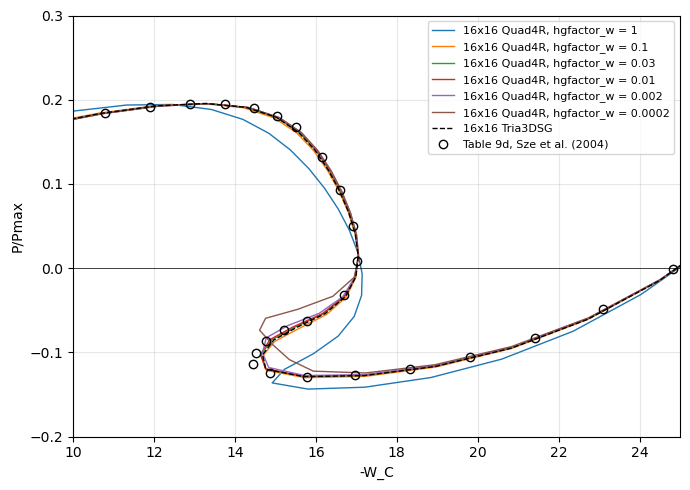

In [10]:
cases = [('Quad4R, hgfactor_w = %g' % hg, dict(hgfactor_w=hg))
         for hg in HGFACTORS] + [('Tria3DSG', dict(element='Tria3DSG'))]
paths_thick, paths_thin = {}, {}
for name, kw in cases:
    if kw.get('hgfactor_w') == 1.:
        # NOTE the path of the 12.7 thick roof with the default, see above
        paths_thick[name] = (P16, W16)
    else:
        paths_thick[name] = run_hinged_roof(n=16, **kw)
    paths_thin[name] = run_hinged_roof(n=16, h=6.35, load_factor=1.1, **kw)


def first_point(P, W, table):
    # NOTE -W_C increases monotonically up to the upper limit point
    rising = W < 10.
    return np.interp(table[0, 1], W[rising], P[rising])


(Pa_r, _), (Pb_r, _) = limit_points(TABLE_9A[:, 0], TABLE_9A[:, 1], 15.)
print('h = 12.7, 16x16, P/Pmax: upper and lower limit loads, load at the '
      'first point of Table 9a')
print('%-28s %9s %9s %9s' % ('', 'upper', 'lower', 'first'))
print('%-28s %9.4f %9.4f %9.4f' % ('Table 9a', Pa_r, Pb_r, TABLE_9A[0, 0]))
for name, (P_, W_) in paths_thick.items():
    (Pa, _), (Pb, _) = limit_points(P_, W_, 15.)
    print('%-28s %9.4f %9.4f %9.4f' % (name, Pa, Pb,
                                       first_point(P_, W_, TABLE_9A)))
(Pa_r, _), _ = limit_points(TABLE_9D[:, 0], TABLE_9D[:, 1], 13.5)
print()
print('h = 6.35, 16x16, P/Pmax: upper and lower limit loads, load at the '
      'first point of Table 9d')
print('%-28s %9s %9s %9s' % ('', 'upper', 'lower', 'first'))
print('%-28s %9.4f %9.4f %9.4f' % ('Table 9d', Pa_r, TABLE_9D[:, 0].min(),
                                   TABLE_9D[0, 0]))
for name, (P_, W_) in paths_thin.items():
    (Pa, _), _ = limit_points(P_, W_, 13.5)
    print('%-28s %9.4f %9.4f %9.4f' % (name, Pa, P_.min(),
                                       first_point(P_, W_, TABLE_9D)))

fig, ax = plt.subplots(figsize=(7, 5))
for (name, (P_, W_)), style in zip(paths_thin.items(),
                                   ['C0-', 'C1-', 'C2-', 'C3-', 'C4-', 'C5-',
                                    'k--']):
    ax.plot(W_, P_, style, lw=1., label='16x16 ' + name)
ax.plot(TABLE_9D[:, 1], TABLE_9D[:, 0], 'ko', mfc='none',
        label='Table 9d, Sze et al. (2004)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('-W_C')
ax.set_ylabel('P/Pmax')
ax.set_xlim(10, 25)
ax.set_ylim(-0.2, 0.3)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

For both thicknesses the default makes the start of the path stiffer, by
7 % ($h = 12.7$) and 8 % ($h = 6.35$) at the first point of the tables,
whereas the reduced values of `hgfactor_w` and `Tria3DSG` are within 1.8 %
of it. The upper limit loads agree within 0.6 % with the tables for all
the values of `hgfactor_w`. The lower limit loads behave
differently: for $h = 12.7$ the default is the closest to Table 9a (-0.9 %),
the reduced values and `Tria3DSG` being 2.3 to 2.9 % below it; for
$h = 6.35$ the default is 0.015 $P_{max}$ below Table 9d, while the values
of `hgfactor_w` from 0.1 to 0.002 and `Tria3DSG` are within 0.0014
$P_{max}$, and 0.0002 is 0.0045 $P_{max}$ above it.

The smaller values of `hgfactor_w` leave the hourglass pattern of $w$ with
little stiffness, and the path then depends more on the mesh and on the
increments: with the $24 \times 24$ mesh and the arc-length increment of
0.02 used above for Table 9d, `hgfactor_w = 0.002` gives another path after
the upper limit point:

In [11]:
P24_002, W24_002 = run_hinged_roof(n=24, h=6.35, load_factor=1.1,
                                   initialInc=0.02, maxInc=0.02,
                                   hgfactor_w=0.002)
(Pa, _), _ = limit_points(P24_002, W24_002, 13.5)
print('24x24 Quad4R, hgfactor_w = 0.002: upper and lower limit loads %.4f, '
      '%.4f; Table 9d: %.4f, %.4f' % (Pa, P24_002.min(), Pa_r,
                                      TABLE_9D[:, 0].min()))
for name, (P_, W_) in [('hgfactor_w = 1, above', (P, W)),
                       ('hgfactor_w = 0.002', (P24_002, W24_002)),
                       ('Table 9d', (TABLE_9D[:, 0], TABLE_9D[:, 1]))]:
    dW = np.diff(W_)
    turns = np.flatnonzero(np.sign(dW[1:]) != np.sign(dW[:-1])) + 1
    print('%-22s turning points of -W_C: %s' % (name, ', '.join(
        'P/Pmax %.4f at -W_C %.3f' % (P_[i], W_[i]) for i in turns)))

24x24 Quad4R, hgfactor_w = 0.002: upper and lower limit loads 0.1948, -0.1112; Table 9d: 0.1953, -0.1288
hgfactor_w = 1, above  turning points of -W_C: P/Pmax -0.0139 at -W_C 17.186, P/Pmax -0.1336 at -W_C 14.850
hgfactor_w = 0.002     turning points of -W_C: P/Pmax 0.0478 at -W_C 16.778, P/Pmax -0.0343 at -W_C 13.970
Table 9d               turning points of -W_C: P/Pmax 0.0083 at -W_C 17.008, P/Pmax -0.1142 at -W_C 14.451


This path turns back in $-W_C$ for the first time at 0.0478 $P_{max}$,
against 0.0083 $P_{max}$ in Table 9d and -0.0139 $P_{max}$ with the default,
and its lower limit load is 0.018 $P_{max}$ above the
smallest load of Table 9d, whereas with the $16 \times 16$ mesh and the
increment of 0.05 the same `hgfactor_w` was within 0.0014 $P_{max}$.

The sensitivity is therefore not a single trend: reducing `hgfactor_w`
removes the excess stiffness of the linear response and of the start of the
non-linear path, and, in the Kirchhoff limit, converges to the independent
solution, but it does not improve every result of the non-linear paths and
it makes them depend more on the mesh and on the increments. The
assertions of the linear trend are in `test_hinged_roof_hourglass_sensitivity`.

Summary
---

| benchmark | reference, Sze et al. (2004) | pyfe3d |
|---|---|---|
| cantilever under end moment | Table 3a, exact, rolls up into a circle | `Quad4R`: the von Karman solution, within 1 % of Table 3a at $M = 0.05 M_{max}$, no roll-up; `BeamC`, `BeamLR`: membrane locking, converging to the von Karman solution with the number of elements |
| hinged roof, $h = 12.7$ | Table 9a | `Quad4R` with the default hourglass stiffness: limit loads within about 1 %; 7 % stiffer at the start, up to 0.06 $P_{max}$ lower on the descending branch |
| hinged roof, $h = 6.35$ | Table 9d | snap-through and snap-back traced; `Quad4R` with the default hourglass stiffness: upper limit load within 0.5 %, lower limit load 0.015 $P_{max}$ lower |
| sensitivity to `hgfactor_w` | Tables 9a and 9d, `Tria3DSG`, shallow-shell Kirchhoff Ritz solution | the default `Quad4R` is 6 to 7 % stiffer in the linear range; smaller values approach the references there, with mixed effects on the limit loads; the default is kept |

The assertions of these comparisons are in
`tests/test_nonlinear_benchmarks_sze2004.py`.